# Conditional GAN 64×64 — AFHQ (versi improved)

Semua improvement bisa dinyalakan/dimatikan lewat flag di `CFG` (Cell 1). Ganti eksperimen cukup dengan mengubah `RUN`.

Sebelum **Run All**:
1. **Add Input**: dataset **Animal Faces** (`andrewmvd`).
2. **Settings → Accelerator**: GPU.
3. **Settings → Internet**: On (untuk FID, KID, Precision/Recall, LPIPS, dan classifier pretrained). Kalau Off, bagian itu otomatis dilewati.
4. Atur `RUN` di Cell 1. Urutan yang disarankan: `A_ema` → `B_sn_hinge` → `C_diffaug` → `D_cond` → `E_arch`, lalu `F*` kalau masih ada waktu.
5. Untuk run pertama, set `SMOKE = True` (2 epoch, sampel sedikit) untuk memastikan semua cell jalan. Setelah itu kembalikan ke `False`.

Input tambahan (opsional, lewat **Add Input**):
- Output run sebelumnya (`cgan_<run>.zip`): untuk **resume** run yang sama dan untuk **perbandingan antar run** (Cell 15).
- Output baseline lama (`cgan_output.zip`, berisi `checkpoint.pt` tanpa `run_name`): baseline dievaluasi ulang dengan protokol yang sama (Cell 12–13).
- `classifier.pt` (ikut tersimpan di zip setiap run): supaya classifier di Cell 13 tidak dilatih ulang.

| Run | Isi |
|---|---|
| `baseline` | setara notebook lama (semua flag mati), 100 epoch |
| `A_ema` | 200 epoch + EMA Generator + LR decay + best checkpoint |
| `B_sn_hinge` | A + Spectral Norm di D + hinge loss + TTUR |
| `C_diffaug` | B + DiffAugment |
| `D_cond` | C + Projection Discriminator + Conditional BatchNorm |
| `E_arch` | D + Upsample-Conv + Self-Attention + Minibatch StdDev |
| `F1_r1` … `F6_bs256` | E + satu eksperimen opsional: R1, AC-GAN, mode-seeking, ResNet G, model lebih lebar, batch 256 |

## Cell 1 — Setup dan konfigurasi

In [1]:
import copy, json, math, os, random, shutil, subprocess, sys, time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, TensorDataset
from torchvision.utils import make_grid, save_image

# ===== Pilih eksperimen =====
RUN = "A_ema"   # baseline | A_ema | B_sn_hinge | C_diffaug | D_cond | E_arch | F1_r1 | F2_ac | F3_ms | F4_resnet | F5_wide | F6_bs256
SMOKE = False   # True = uji cepat (2 epoch, sampel sedikit) untuk cek error

BASE = {
    "img_size": 64, "batch_size": 128, "z_dim": 100, "embed_dim": 50,
    "g_base": 64, "d_base": 64,
    "epochs": 100,
    # optimizer
    "lr_G": 2e-4, "lr_D": 2e-4, "betas": (0.5, 0.999),
    "lr_decay_start": 1.0,     # LR turun linear ke 0 mulai (x * epochs); 1.0 = tanpa decay
    "amp": False,              # mixed precision; otomatis mati kalau R1 aktif atau tanpa GPU
    # loss
    "loss": "bce",             # "bce" | "hinge"
    "real_label": 0.9,         # label smoothing, hanya dipakai kalau loss = "bce"
    "r1_gamma": 0.0, "r1_every": 16,
    "ac_weight": 0.0,          # AC-GAN (0 = mati)
    "ms_weight": 0.0,          # mode-seeking (0 = mati)
    # arsitektur
    "spectral_norm": False, "projection_d": False, "cond_bn": False,
    "upsample_conv": False, "self_attn": False, "mbstd": False, "resnet_g": False,
    # augmentasi & EMA
    "diffaug": "",             # contoh: "color,translation,cutout"
    "ema": False, "ema_decay": 0.999, "ema_start": 1000,   # ema_start dalam iterasi
    # evaluasi
    "fid_every": 10, "fid_samples": 10000, "ckpt_every": 10,
    "use_fid": True, "resume": True, "seed": 42,
    "clf_epochs": 4, "eval_fake_per_class": 5000,
}

# Setiap run mewarisi run sebelumnya lalu menambah satu kelompok perubahan (ablation).
P_A = {"epochs": 200, "ema": True, "lr_decay_start": 0.7}
P_B = {**P_A, "loss": "hinge", "spectral_norm": True, "lr_G": 1e-4, "lr_D": 4e-4, "betas": (0.0, 0.9)}
P_C = {**P_B, "diffaug": "color,translation,cutout"}
P_D = {**P_C, "projection_d": True, "cond_bn": True}
P_E = {**P_D, "upsample_conv": True, "self_attn": True, "mbstd": True}
PRESETS = {
    "baseline": {}, "A_ema": P_A, "B_sn_hinge": P_B, "C_diffaug": P_C, "D_cond": P_D, "E_arch": P_E,
    "F1_r1": {**P_E, "r1_gamma": 0.1},
    "F2_ac": {**P_E, "ac_weight": 0.5},
    "F3_ms": {**P_E, "ms_weight": 0.1},
    "F4_resnet": {**P_E, "resnet_g": True},
    "F5_wide": {**P_E, "g_base": 96, "d_base": 96},
    "F6_bs256": {**P_E, "batch_size": 256, "lr_G": 1.4e-4, "lr_D": 5.6e-4},
}
CFG = {**BASE, **PRESETS[RUN], "run_name": RUN}
if SMOKE:
    CFG.update(run_name=RUN + "_smoke", epochs=2, fid_every=1, ckpt_every=1, fid_samples=1000,
               clf_epochs=1, eval_fake_per_class=500)

random.seed(CFG["seed"])
np.random.seed(CFG["seed"])
torch.manual_seed(CFG["seed"])
torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = CFG["amp"] and DEVICE.type == "cuda" and CFG["r1_gamma"] == 0
WORK_DIR = Path("/kaggle/working")
OUT = WORK_DIR / f"cgan_{CFG['run_name']}"
(OUT / "samples").mkdir(parents=True, exist_ok=True)
(OUT / "config.json").write_text(json.dumps(CFG, indent=1))

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold",
})
SERIES = ["#2a78d6", "#eb6834"]

print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "(GPU tidak aktif!)")
print("Run:", CFG["run_name"], "| output:", OUT, "| AMP:", AMP)

Device: cuda Tesla T4
Run: A_ema | output: /kaggle/working/cgan_A_ema | AMP: False


## Cell 2 — Load dataset ke RAM (64×64, train + val)

In [2]:
def find_dataset_root():
    for folder, subdirs, _ in os.walk("/kaggle/input"):
        if "train" in subdirs and "cat" in os.listdir(Path(folder) / "train"):
            return Path(folder)
    raise FileNotFoundError("Dataset belum ditambahkan. Klik Add Input, pilih Animal Faces dari andrewmvd.")


IMG = CFG["img_size"]
ROOT = find_dataset_root()
CLASSES = sorted(p.name for p in (ROOT / "train").iterdir() if p.is_dir())
N_CLASSES = len(CLASSES)


def load_image(path):
    with Image.open(path) as im:
        im.draft("RGB", (IMG * 2, IMG * 2))  # decode JPEG langsung di ukuran kecil, jauh lebih cepat
        return np.asarray(im.convert("RGB").resize((IMG, IMG), Image.BICUBIC), dtype=np.uint8)


def load_split(split):
    paths, lbl = [], []
    for label, cls in enumerate(CLASSES):
        files = sorted(p for p in (ROOT / split / cls).iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
        paths += files
        lbl += [label] * len(files)
    with ThreadPoolExecutor(max_workers=os.cpu_count() or 2) as pool:
        arr = np.stack(list(pool.map(load_image, paths)))
    # Disimpan sebagai uint8 (hemat RAM); diubah ke float [-1, 1] per batch di GPU.
    return torch.from_numpy(arr).permute(0, 3, 1, 2).contiguous(), torch.tensor(lbl, dtype=torch.long)


images, labels = load_split("train")
if (ROOT / "val").exists():
    val_images, val_labels = load_split("val")
else:
    val_images, val_labels = None, None
    print("Split val tidak ditemukan: evaluasi vs val dan validasi classifier dilewati.")

loader = DataLoader(TensorDataset(images, labels), batch_size=CFG["batch_size"], shuffle=True,
                    drop_last=True, pin_memory=DEVICE.type == "cuda")


def prepare_batch(imgs):
    x = imgs.to(DEVICE, non_blocking=True).float().div(127.5).sub(1)  # [0, 255] -> [-1, 1]
    flip = torch.rand(x.size(0), device=DEVICE) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)


print("Kelas:", dict(enumerate(CLASSES)))
print("Train:", tuple(images.shape), "| batch per epoch:", len(loader))
print("Val  :", None if val_images is None else tuple(val_images.shape))

Kelas: {0: 'cat', 1: 'dog', 2: 'wild'}
Train: (14630, 3, 64, 64) | batch per epoch: 114
Val  : (1500, 3, 64, 64)


## Cell 2b — DiffAugment

Augmentasi diferensiabel (Zhao dkk., 2020) diterapkan ke **input discriminator**, baik gambar asli maupun palsu, bukan ke dataset. Karena semua operasinya diferensiabel, gradien tetap mengalir ke generator. Tujuannya mencegah D menghafal ±15k gambar training. Kalau `CFG["diffaug"]` kosong, `diff_augment` tidak mengubah apa-apa.

In [3]:
def aug_color(x):
    B = x.size(0)
    x = x + (torch.rand(B, 1, 1, 1, device=x.device) - 0.5)                  # brightness
    m = x.mean(dim=1, keepdim=True)
    x = (x - m) * (torch.rand(B, 1, 1, 1, device=x.device) * 2) + m          # saturation
    m = x.mean(dim=[1, 2, 3], keepdim=True)
    return (x - m) * (torch.rand(B, 1, 1, 1, device=x.device) + 0.5) + m     # contrast


def aug_translation(x, ratio=0.125):
    B = x.size(0)
    theta = torch.zeros(B, 2, 3, device=x.device)
    theta[:, 0, 0] = theta[:, 1, 1] = 1
    theta[:, :, 2] = (torch.rand(B, 2, device=x.device) * 2 - 1) * ratio * 2   # geser maks 12.5% sisi
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode="nearest", padding_mode="zeros", align_corners=False)


def aug_cutout(x, ratio=0.5):
    B, _, H, W = x.shape
    ch, cw = int(H * ratio + 0.5), int(W * ratio + 0.5)
    cy = torch.randint(0, H, (B, 1, 1), device=x.device)
    cx = torch.randint(0, W, (B, 1, 1), device=x.device)
    yy = torch.arange(H, device=x.device).view(1, H, 1)
    xx = torch.arange(W, device=x.device).view(1, 1, W)
    keep = ((yy - cy).abs() >= ch // 2) | ((xx - cx).abs() >= cw // 2)
    return x * keep[:, None].float()


AUGS = {"color": aug_color, "translation": aug_translation, "cutout": aug_cutout}
POLICY = [AUGS[p.strip()] for p in CFG["diffaug"].split(",") if p.strip()]


def diff_augment(x):
    if not POLICY:
        return x
    x = x.float()  # aman untuk AMP
    for fn in POLICY:
        x = fn(x)
    return x


print("DiffAugment:", CFG["diffaug"] or "mati")

DiffAugment: mati


## Cell 3 — Cek data

Shape batch : (128, 3, 64, 64)
Rentang     : -1.0 sampai 1.0
Label batch : {'cat': 36, 'dog': 45, 'wild': 47}


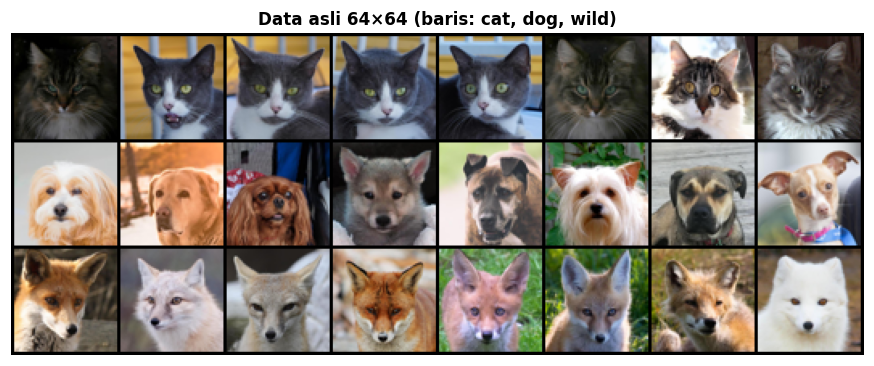

In [4]:
imgs, lbls = next(iter(loader))
x = prepare_batch(imgs)
print("Shape batch :", tuple(x.shape))
print("Rentang     :", round(x.min().item(), 3), "sampai", round(x.max().item(), 3))
print("Label batch :", {CLASSES[k]: int(v) for k, v in zip(*torch.unique(lbls, return_counts=True))})

per_class = torch.cat([images[labels == c][:8] for c in range(N_CLASSES)])
grid = make_grid(per_class, nrow=8, padding=2)
plt.figure(figsize=(10, 4))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Data asli 64×64 (baris: " + ", ".join(CLASSES) + ")")
plt.show()

# Preview DiffAugment: atas = asli, bawah = setelah augmentasi
if POLICY:
    sample = prepare_batch(per_class[:8].clone())
    aug = diff_augment(sample)
    grid = make_grid(torch.cat([sample, aug]).cpu(), nrow=8, padding=2, normalize=True, value_range=(-1, 1))
    plt.figure(figsize=(10, 2.8))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    plt.title("Atas: asli | Bawah: DiffAugment (" + CFG["diffaug"] + ")")
    plt.show()

## Cell 4 — Generator

Flag yang berpengaruh:
- `cond_bn`: Conditional BatchNorm. Label masuk ke **setiap** layer lewat gamma/beta per kelas, bukan hanya di input.
- `upsample_conv`: Upsample (nearest) + Conv 3×3 menggantikan ConvTranspose, untuk mengurangi artefak checkerboard.
- `self_attn`: Self-Attention (SAGAN) di resolusi 32×32, supaya struktur wajah lebih koheren secara global.
- `resnet_g`: blok residual.

Kalau semua flag mati, struktur ini setara dengan Generator DCGAN lama (tapi nama layernya berbeda, jadi checkpoint lama tidak bisa di-load ke sini; lihat `GeneratorV1` di Cell 12).

In [5]:
class PlainBN(nn.BatchNorm2d):
    # BatchNorm biasa yang menerima argumen label (diabaikan), supaya bisa ditukar dengan CondBN
    def forward(self, x, y=None):
        return super().forward(x)


class CondBN(nn.Module):
    # BatchNorm dengan gamma/beta per kelas
    def __init__(self, ch, n_classes):
        super().__init__()
        self.bn = nn.BatchNorm2d(ch, affine=False)
        self.gamma = nn.Embedding(n_classes, ch)
        self.beta = nn.Embedding(n_classes, ch)
        nn.init.ones_(self.gamma.weight)
        nn.init.zeros_(self.beta.weight)

    def forward(self, x, y):
        return self.bn(x) * self.gamma(y)[:, :, None, None] + self.beta(y)[:, :, None, None]


class SelfAttention(nn.Module):
    # SAGAN. gamma mulai dari 0, jadi di awal training attention belum berpengaruh.
    def __init__(self, ch, sn=lambda m: m):
        super().__init__()
        self.q = sn(nn.Conv2d(ch, ch // 8, 1, bias=False))
        self.k = sn(nn.Conv2d(ch, ch // 8, 1, bias=False))
        self.v = sn(nn.Conv2d(ch, ch, 1, bias=False))
        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        B, C, H, W = x.shape
        q = self.q(x).flatten(2).transpose(1, 2).unsqueeze(1)   # B, 1, HW, C/8
        k = self.k(x).flatten(2).transpose(1, 2).unsqueeze(1)
        v = self.v(x).flatten(2).transpose(1, 2).unsqueeze(1)   # B, 1, HW, C
        out = F.scaled_dot_product_attention(q, k, v)           # lebih hemat memori
        out = out.squeeze(1).transpose(1, 2).reshape(B, C, H, W)
        return x + self.gamma * out


class GBlock(nn.Module):
    # Upsample 2x. Varian: ConvTranspose (lama) | Upsample + Conv | residual
    def __init__(self, c_in, c_out, norm, cfg):
        super().__init__()
        self.resnet = cfg["resnet_g"]
        if self.resnet:
            self.n1, self.n2 = norm(c_in), norm(c_out)
            self.c1 = nn.Conv2d(c_in, c_out, 3, 1, 1)
            self.c2 = nn.Conv2d(c_out, c_out, 3, 1, 1)
            self.skip = nn.Conv2d(c_in, c_out, 1)
        else:
            if cfg["upsample_conv"]:
                self.conv = nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"),
                                          nn.Conv2d(c_in, c_out, 3, 1, 1, bias=False))
            else:
                self.conv = nn.ConvTranspose2d(c_in, c_out, 4, 2, 1, bias=False)
            self.n = norm(c_out)

    def forward(self, x, y):
        if self.resnet:
            h = F.interpolate(F.relu(self.n1(x, y)), scale_factor=2)
            h = self.c2(F.relu(self.n2(self.c1(h), y)))
            return h + self.skip(F.interpolate(x, scale_factor=2))
        return F.relu(self.n(self.conv(x), y))


class Generator(nn.Module):
    # noise + label -> gambar 64x64
    def __init__(self, cfg, n_classes):
        super().__init__()
        z_dim, e, b = cfg["z_dim"], cfg["embed_dim"], cfg["g_base"]
        norm = (lambda c: CondBN(c, n_classes)) if cfg["cond_bn"] else PlainBN
        self.label_embed = nn.Embedding(n_classes, e)
        self.stem = nn.ConvTranspose2d(z_dim + e, b * 8, 4, 1, 0, bias=False)            # 1 -> 4
        self.stem_norm = norm(b * 8)
        ch = [b * 8, b * 4, b * 2, b]
        self.blocks = nn.ModuleList(GBlock(ch[i], ch[i + 1], norm, cfg) for i in range(3))  # 4 -> 8 -> 16 -> 32
        self.attn = SelfAttention(b) if cfg["self_attn"] else nn.Identity()                # di 32x32
        self.out_norm = norm(b) if cfg["resnet_g"] else None
        if cfg["upsample_conv"] or cfg["resnet_g"]:
            self.to_rgb = nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"), nn.Conv2d(b, 3, 3, 1, 1))
        else:
            self.to_rgb = nn.ConvTranspose2d(b, 3, 4, 2, 1)                                 # 32 -> 64

    def forward(self, z, y):
        h = torch.cat([z, self.label_embed(y)], dim=1)[:, :, None, None]
        h = F.relu(self.stem_norm(self.stem(h), y))
        for blk in self.blocks:
            h = blk(h, y)
        h = self.attn(h)
        if self.out_norm is not None:
            h = F.relu(self.out_norm(h, y))
        return torch.tanh(self.to_rgb(h))

## Cell 5 — Discriminator

Flag yang berpengaruh:
- `spectral_norm`: Spectral Normalization menggantikan BatchNorm, supaya D tidak makin dominan.
- `projection_d`: Projection Discriminator. Label masuk lewat perkalian dalam embedding kelas dengan fitur akhir, bukan sebagai channel ke-4 di input.
- `self_attn`: Self-Attention di 16×16.
- `mbstd`: Minibatch Standard Deviation. D bisa melihat kalau sampel dalam satu batch terlalu mirip, sehingga G didorong lebih beragam.
- `ac_weight > 0`: head klasifikasi AC-GAN.

D sekarang mengembalikan `(skor, logit_kelas)`. `logit_kelas` bernilai `None` kalau AC-GAN mati.

In [6]:
def minibatch_std(x, group=4):
    # Tambah 1 channel: rata-rata std fitur di dalam grup sampel (dihitung di float32 supaya aman untuk AMP)
    B, C, H, W = x.shape
    g = min(group, B)
    while B % g:
        g -= 1
    s = x.float().view(g, -1, C, H, W)
    s = (s - s.mean(0)).pow(2).mean(0).add(1e-8).sqrt()
    s = s.mean(dim=[1, 2, 3]).view(-1, 1, 1, 1).repeat(g, 1, H, W)
    return torch.cat([x, s.to(x.dtype)], dim=1)


class Discriminator(nn.Module):
    # gambar + label -> skor asli/palsu (logit, tanpa sigmoid)
    def __init__(self, cfg, n_classes):
        super().__init__()
        b, img = cfg["d_base"], cfg["img_size"]
        self.img = img
        self.use_mbstd = cfg["mbstd"]
        self.use_ac = cfg["ac_weight"] > 0
        sn_on = cfg["spectral_norm"]
        SN = nn.utils.spectral_norm if sn_on else (lambda m: m)

        def down(c_in, c_out, bn):
            layers = [SN(nn.Conv2d(c_in, c_out, 4, 2, 1, bias=not bn or sn_on))]
            if bn and not sn_on:  # Spectral Norm menggantikan BatchNorm
                layers.append(nn.BatchNorm2d(c_out))
            return layers + [nn.LeakyReLU(0.2, True)]

        self.projection = cfg["projection_d"]
        if not self.projection:  # cara lama: label jadi 1 channel 64x64 di input
            self.label_map = nn.Embedding(n_classes, img * img)
        in_ch = 3 if self.projection else 4

        self.block1 = nn.Sequential(*down(in_ch, b, False), *down(b, b * 2, True))         # 64 -> 16
        self.attn = SelfAttention(b * 2, SN) if cfg["self_attn"] else nn.Identity()         # di 16x16
        self.block2 = nn.Sequential(*down(b * 2, b * 4, True), *down(b * 4, b * 8, True))  # 16 -> 4

        extra = 1 if self.use_mbstd else 0
        self.vec_head = self.projection or self.use_ac
        if self.vec_head:  # head berbasis vektor fitur (dibutuhkan projection / AC-GAN)
            self.final = nn.Sequential(SN(nn.Conv2d(b * 8 + extra, b * 8, 3, 1, 1)), nn.LeakyReLU(0.2, True))
            self.linear = SN(nn.Linear(b * 8, 1))
            if self.projection:
                emb = nn.Embedding(n_classes, b * 8)
                nn.init.xavier_uniform_(emb.weight)
                self.embed = SN(emb)
            if self.use_ac:
                self.cls = nn.Linear(b * 8, n_classes)
        else:  # head lama: conv 4x4 -> 1
            self.final = SN(nn.Conv2d(b * 8 + extra, 1, 4, 1, 0))

    def forward(self, x, y):
        if not self.projection:
            x = torch.cat([x, self.label_map(y).view(-1, 1, self.img, self.img)], dim=1)
        h = self.block2(self.attn(self.block1(x)))
        if self.use_mbstd:
            h = minibatch_std(h)
        if not self.vec_head:
            return self.final(h).view(-1), None
        h = self.final(h).sum(dim=[2, 3])  # global sum pooling
        out = self.linear(h).squeeze(1)
        if self.projection:
            out = out + (self.embed(y) * h).sum(dim=1)
        cls = self.cls(h) if self.use_ac else None
        return out, cls


def init_weights(m):
    # Inisialisasi standar DCGAN
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, nn.BatchNorm2d) and m.affine:  # BN di dalam CondBN tidak punya weight (affine=False)
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)


G = Generator(CFG, N_CLASSES).to(DEVICE)
D = Discriminator(CFG, N_CLASSES).to(DEVICE)
G.apply(init_weights)
if not CFG["spectral_norm"]:
    # Dengan Spectral Norm, init ke m.weight tidak berefek (bobot aslinya ada di weight_orig),
    # jadi D ber-SN memakai init default PyTorch seperti di SNGAN.
    D.apply(init_weights)

## Cell 6 — Cek model

In [7]:
with torch.no_grad():
    z = torch.randn(4, CFG["z_dim"], device=DEVICE)
    y = torch.randint(0, N_CLASSES, (4,), device=DEVICE)
    fake = G(z, y)
    score, cls = D(fake, y)

assert fake.shape == (4, 3, IMG, IMG), fake.shape
assert score.shape == (4,), score.shape
assert (cls is None) == (CFG["ac_weight"] == 0)
if cls is not None:
    assert cls.shape == (4, N_CLASSES), cls.shape

FLAGS = ["loss", "ema", "spectral_norm", "projection_d", "cond_bn", "upsample_conv", "self_attn",
         "mbstd", "resnet_g", "diffaug", "r1_gamma", "ac_weight", "ms_weight"]
print("Flag aktif:", {k: CFG[k] for k in FLAGS if CFG[k]})
print("Output G:", tuple(fake.shape), "rentang", round(fake.min().item(), 3), "-", round(fake.max().item(), 3))
print("Output D:", tuple(score.shape), "| logit kelas:", None if cls is None else tuple(cls.shape))
print(f"Parameter G: {sum(p.numel() for p in G.parameters()):,}")
print(f"Parameter D: {sum(p.numel() for p in D.parameters()):,}")

Flag aktif: {'loss': 'bce', 'ema': True}
Output G: (4, 3, 64, 64) rentang -0.776 - 0.801
Output D: (4,) | logit kelas: None
Parameter G: 3,986,457
Parameter D: 2,778,945


## Cell 7 — Loss, optimizer, LR decay, dan EMA

- **Loss**: `bce` (seperti sebelumnya, dengan label smoothing) atau `hinge`.
- **TTUR**: learning rate dan betas G/D diatur terpisah lewat `lr_G`, `lr_D`, `betas`.
- **LR decay**: turun linear ke 0 mulai `lr_decay_start × epochs`.
- **EMA**: `G_ema` adalah rata-rata bergerak bobot G. Sampel, FID, dan semua hasil akhir memakai `G_eval` (= `G_ema` kalau EMA aktif).

In [8]:
criterion = nn.BCEWithLogitsLoss()
ce = nn.CrossEntropyLoss()


def d_adv_loss(real_out, fake_out):
    if CFG["loss"] == "hinge":
        return F.relu(1 - real_out).mean() + F.relu(1 + fake_out).mean()
    return (criterion(real_out, torch.full_like(real_out, CFG["real_label"]))
            + criterion(fake_out, torch.zeros_like(fake_out)))


def g_adv_loss(fake_out):
    if CFG["loss"] == "hinge":
        return -fake_out.mean()
    return criterion(fake_out, torch.ones_like(fake_out))


opt_G = torch.optim.Adam(G.parameters(), lr=CFG["lr_G"], betas=tuple(CFG["betas"]))
opt_D = torch.optim.Adam(D.parameters(), lr=CFG["lr_D"], betas=tuple(CFG["betas"]))

DECAY_FROM = int(CFG["epochs"] * CFG["lr_decay_start"])


def lr_factor(e):  # e = jumlah epoch yang sudah selesai
    if e < DECAY_FROM:
        return 1.0
    return max(0.0, (CFG["epochs"] - e) / max(1, CFG["epochs"] - DECAY_FROM))


sched_G = torch.optim.lr_scheduler.LambdaLR(opt_G, lr_factor)
sched_D = torch.optim.lr_scheduler.LambdaLR(opt_D, lr_factor)

try:
    scaler_G = torch.amp.GradScaler("cuda", enabled=AMP)
    scaler_D = torch.amp.GradScaler("cuda", enabled=AMP)
except (AttributeError, TypeError):  # versi PyTorch lama
    scaler_G = torch.cuda.amp.GradScaler(enabled=AMP)
    scaler_D = torch.cuda.amp.GradScaler(enabled=AMP)

G_ema = copy.deepcopy(G).eval().requires_grad_(False) if CFG["ema"] else None
G_eval = G_ema if CFG["ema"] else G


@torch.no_grad()
def update_ema(step):
    d = CFG["ema_decay"] if step >= CFG["ema_start"] else 0.0  # sebelum ema_start: salin langsung
    for pe, p in zip(G_ema.parameters(), G.parameters()):
        pe.lerp_(p, 1 - d)
    for be, b in zip(G_ema.buffers(), G.buffers()):  # running stats BatchNorm ikut disalin
        be.copy_(b)


@torch.no_grad()
def generate(z, y, model=None):
    # Selalu generate dalam mode eval, lalu kembalikan mode semula
    m = G_eval if model is None else model
    was_training = m.training
    m.eval()
    out = m(z, y)
    m.train(was_training)
    return out


@torch.no_grad()
def generate_many(z, y, model=None, bs=250):
    return torch.cat([generate(z[i:i + bs], y[i:i + bs], model) for i in range(0, len(z), bs)])

## Cell 8 — Fungsi evaluasi (grid sampel, FID, truncation)

Protokol FID dikunci supaya angka antar epoch dan antar run bisa dibandingkan: subset gambar asli memakai seed tetap, noise dan label gambar palsu juga memakai seed tetap, dan label dibagi rata per kelas.

In [9]:
# Noise tetap: 8 sampel per kelas, dipakai tiap epoch supaya perkembangan bisa dibandingkan.
fixed_gen = torch.Generator().manual_seed(CFG["seed"])
fixed_z = torch.randn(8 * N_CLASSES, CFG["z_dim"], generator=fixed_gen).to(DEVICE)
fixed_y = torch.arange(N_CLASSES).repeat_interleave(8).to(DEVICE)


def sample_z(n, gen=None, trunc=None):
    # trunc = truncation trick: nilai |z| > trunc diambil ulang. Hanya untuk demo, bukan untuk FID training.
    z = torch.randn(n, CFG["z_dim"], generator=gen)
    if trunc is not None:
        mask = z.abs() > trunc
        while mask.any():
            z[mask] = torch.randn(int(mask.sum()), generator=gen)
            mask = z.abs() > trunc
    return z.to(DEVICE)


def to_uint8(x):  # [-1, 1] -> uint8 [0, 255] di CPU
    return ((x.float() + 1) * 127.5).round().clamp(0, 255).to(torch.uint8).cpu()


@torch.no_grad()
def gen_uint8(model, cls, n, seed, trunc=None):
    g = torch.Generator().manual_seed(seed)
    return to_uint8(generate_many(sample_z(n, g, trunc), torch.full((n,), cls, device=DEVICE), model))


def save_sample_grid(epoch):
    save_image(generate(fixed_z, fixed_y), OUT / "samples" / f"epoch_{epoch:03d}.png",
               nrow=8, normalize=True, value_range=(-1, 1))


fid_enabled = CFG["use_fid"]
fid = None
if fid_enabled:
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torch-fidelity", "torchmetrics"], check=True)
        from torchmetrics.image.fid import FrechetInceptionDistance

        fid = FrechetInceptionDistance(feature=2048, normalize=True, reset_real_features=False).to(DEVICE)
        real_idx = torch.randperm(len(images), generator=torch.Generator().manual_seed(1234))[:CFG["fid_samples"]]
        for i in range(0, len(real_idx), 250):
            fid.update(images[real_idx[i:i + 250]].to(DEVICE).float() / 255, real=True)
        print("FID aktif. Statistik gambar asli:", len(real_idx), "gambar | sampel palsu:", CFG["fid_samples"])
    except Exception as e:
        fid_enabled = False
        print("FID dilewati (cek Settings → Internet):", type(e).__name__, e)


@torch.no_grad()
def compute_fid(model=None, trunc=None):
    fid.reset()  # hanya menghapus statistik gambar palsu
    gen = torch.Generator().manual_seed(CFG["seed"] + 7)
    n = CFG["fid_samples"]
    ys = torch.arange(N_CLASSES).repeat(math.ceil(n / N_CLASSES))[:n]
    for i in range(0, n, 250):
        y = ys[i:i + 250].to(DEVICE)
        fake = generate(sample_z(len(y), gen, trunc), y, model)
        fid.update((fake.float() + 1) / 2, real=False)
    return fid.compute().item()

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 155MB/s]


FID aktif. Statistik gambar asli: 10000 gambar | sampel palsu: 10000


## Cell 9 — Training loop

- **Resume** otomatis kalau ada `checkpoint.pt` dengan `run_name` yang sama, baik di folder output maupun di `/kaggle/input`. Checkpoint dari run lain tidak akan ikut ter-load.
- **`best.pt`** disimpan setiap kali FID membaik dan dipakai untuk semua hasil akhir.
- Skor D yang dicatat sekarang berupa **logit mentah** (`D_real`, `D_fake`), karena sigmoid tidak bermakna untuk hinge loss. Untuk `bce`, `D_x` dan `D_G_z` (sigmoid) tetap dicatat.

In [10]:
ckpt_path = OUT / "checkpoint.pt"
best_path = OUT / "best.pt"
history, start_epoch, step, best_fid = [], 1, 0, float("inf")


def find_resume():
    if ckpt_path.exists():
        return ckpt_path
    for p in sorted(Path("/kaggle/input").glob("**/checkpoint.pt")):
        try:
            if torch.load(p, map_location="cpu", weights_only=False).get("cfg", {}).get("run_name") == CFG["run_name"]:
                return p
        except Exception:
            pass
    return None


if CFG["resume"]:
    found = find_resume()
    if found is not None:
        ckpt = torch.load(found, map_location=DEVICE, weights_only=False)
        G.load_state_dict(ckpt["G"])
        D.load_state_dict(ckpt["D"])
        if G_ema is not None and ckpt.get("G_ema") is not None:
            G_ema.load_state_dict(ckpt["G_ema"])
        opt_G.load_state_dict(ckpt["opt_G"])
        opt_D.load_state_dict(ckpt["opt_D"])
        sched_G.load_state_dict(ckpt["sched_G"])
        sched_D.load_state_dict(ckpt["sched_D"])
        scaler_G.load_state_dict(ckpt["scaler_G"])
        scaler_D.load_state_dict(ckpt["scaler_D"])
        history, start_epoch = ckpt["history"], ckpt["epoch"] + 1
        step, best_fid = ckpt["step"], ckpt["best_fid"]
        if found.parent != OUT:  # resume dari Add Input: bawa juga best.pt dan grid sampel lama
            if (found.parent / "best.pt").exists() and not best_path.exists():
                shutil.copy(found.parent / "best.pt", best_path)
            if (found.parent / "samples").exists():
                shutil.copytree(found.parent / "samples", OUT / "samples", dirs_exist_ok=True)
        print("Lanjut dari", found, "epoch", ckpt["epoch"], "| best FID", best_fid)


def save_checkpoint(epoch):
    torch.save({"G": G.state_dict(), "D": D.state_dict(),
                "G_ema": G_ema.state_dict() if G_ema is not None else None,
                "opt_G": opt_G.state_dict(), "opt_D": opt_D.state_dict(),
                "sched_G": sched_G.state_dict(), "sched_D": sched_D.state_dict(),
                "scaler_G": scaler_G.state_dict(), "scaler_D": scaler_D.state_dict(),
                "history": history, "epoch": epoch, "step": step, "best_fid": best_fid, "cfg": CFG}, ckpt_path)


def save_best(epoch, fid_value):
    torch.save({"G": G_eval.state_dict(), "epoch": epoch, "fid": fid_value, "cfg": CFG}, best_path)


def autocast():
    return torch.autocast("cuda", enabled=AMP)


G.train()
D.train()
for epoch in range(start_epoch, CFG["epochs"] + 1):
    t0 = time.time()
    sums = defaultdict(float)

    for imgs, y in loader:
        real = prepare_batch(imgs)
        y = y.to(DEVICE, non_blocking=True)
        z = torch.randn(real.size(0), CFG["z_dim"], device=DEVICE)
        with autocast():
            fake = G(z, y)

        # 1) Latih D
        opt_D.zero_grad(set_to_none=True)
        real_in = diff_augment(real)
        do_r1 = CFG["r1_gamma"] > 0 and step % CFG["r1_every"] == 0
        if do_r1:
            real_in = real_in.detach().requires_grad_(True)
        with autocast():
            out_real, cls_real = D(real_in, y)
            out_fake, _ = D(diff_augment(fake.detach()), y)
            loss_D = d_adv_loss(out_real, out_fake)
            if cls_real is not None:  # AC-GAN: D juga belajar menebak kelas gambar asli
                loss_D = loss_D + CFG["ac_weight"] * ce(cls_real, y)
        if do_r1:  # lazy R1 gradient penalty (AMP otomatis mati kalau R1 aktif)
            grad, = torch.autograd.grad(out_real.sum(), real_in, create_graph=True)
            loss_D = loss_D + CFG["r1_gamma"] / 2 * grad.pow(2).flatten(1).sum(1).mean() * CFG["r1_every"]
        scaler_D.scale(loss_D).backward()
        scaler_D.step(opt_D)
        scaler_D.update()

        # 2) Latih G: buat D menilai gambar palsu sebagai asli
        opt_G.zero_grad(set_to_none=True)
        with autocast():
            out_gen, cls_gen = D(diff_augment(fake), y)
            loss_G = g_adv_loss(out_gen)
            if cls_gen is not None:  # AC-GAN: gambar palsu harus dikenali sebagai kelas yang diminta
                loss_G = loss_G + CFG["ac_weight"] * ce(cls_gen, y)
            if CFG["ms_weight"] > 0:  # mode-seeking: z berbeda harus menghasilkan gambar berbeda
                z2 = torch.randn_like(z)
                fake2 = G(z2, y)
                ratio = (fake - fake2).abs().mean(dim=[1, 2, 3]) / (z - z2).abs().mean(dim=1)
                loss_G = loss_G + CFG["ms_weight"] * (1 / (ratio + 1e-5)).mean()
        scaler_G.scale(loss_G).backward()
        scaler_G.step(opt_G)
        scaler_G.update()

        if G_ema is not None:
            update_ema(step)
        step += 1

        sums["loss_D"] += loss_D.item()
        sums["loss_G"] += loss_G.item()
        sums["D_real"] += out_real.float().mean().item()
        sums["D_fake"] += out_fake.float().mean().item()
        if CFG["loss"] == "bce":
            sums["D_x"] += torch.sigmoid(out_real.float()).mean().item()
            sums["D_G_z"] += torch.sigmoid(out_fake.float()).mean().item()
        if cls_real is not None:
            sums["acc_cls"] += (cls_real.argmax(1) == y).float().mean().item()

    record = {"epoch": epoch, **{k: v / len(loader) for k, v in sums.items()},
              "lr_G": opt_G.param_groups[0]["lr"], "detik": time.time() - t0}
    sched_G.step()
    sched_D.step()

    save_sample_grid(epoch)
    is_ckpt_epoch = epoch % CFG["ckpt_every"] == 0 or epoch == CFG["epochs"]
    if fid_enabled and (epoch % CFG["fid_every"] == 0 or epoch == CFG["epochs"]):
        record["fid"] = compute_fid()
        if record["fid"] < best_fid:
            best_fid = record["fid"]
            save_best(epoch, best_fid)
    elif not fid_enabled and is_ckpt_epoch:
        save_best(epoch, float("nan"))  # tanpa FID: "best" = model terbaru
    history.append(record)
    pd.DataFrame(history).to_csv(OUT / "history.csv", index=False)

    msg = (f"Epoch {epoch:3d} | loss_D {record['loss_D']:.3f} | loss_G {record['loss_G']:.3f} | "
           f"D_real {record['D_real']:+.2f} | D_fake {record['D_fake']:+.2f}")
    if "fid" in record:
        msg += f" | FID {record['fid']:.2f}" + (" (best)" if record["fid"] == best_fid else "")
    print(msg + f" | lr_G {record['lr_G']:.1e} | {record['detik']:.0f} dtk")

    if is_ckpt_epoch:
        save_checkpoint(epoch)

Epoch   1 | loss_D 1.174 | loss_G 6.070 | D_real +1.78 | D_fake -2.57 | lr_G 2.0e-04 | 19 dtk
Epoch   2 | loss_D 0.792 | loss_G 5.769 | D_real +1.98 | D_fake -2.62 | lr_G 2.0e-04 | 16 dtk
Epoch   3 | loss_D 0.787 | loss_G 4.604 | D_real +1.67 | D_fake -2.15 | lr_G 2.0e-04 | 16 dtk
Epoch   4 | loss_D 0.780 | loss_G 5.072 | D_real +1.66 | D_fake -2.43 | lr_G 2.0e-04 | 16 dtk
Epoch   5 | loss_D 0.729 | loss_G 4.740 | D_real +1.84 | D_fake -2.39 | lr_G 2.0e-04 | 17 dtk
Epoch   6 | loss_D 0.744 | loss_G 4.885 | D_real +1.71 | D_fake -2.44 | lr_G 2.0e-04 | 17 dtk
Epoch   7 | loss_D 0.835 | loss_G 4.925 | D_real +1.60 | D_fake -2.38 | lr_G 2.0e-04 | 17 dtk
Epoch   8 | loss_D 0.765 | loss_G 4.751 | D_real +1.64 | D_fake -2.22 | lr_G 2.0e-04 | 17 dtk
Epoch   9 | loss_D 0.772 | loss_G 4.862 | D_real +1.70 | D_fake -2.45 | lr_G 2.0e-04 | 17 dtk
Epoch  10 | loss_D 0.794 | loss_G 4.422 | D_real +1.58 | D_fake -2.27 | FID 240.83 (best) | lr_G 2.0e-04 | 18 dtk
Epoch  11 | loss_D 0.780 | loss_G 4.206 

## Cell 10 — Grafik metrik

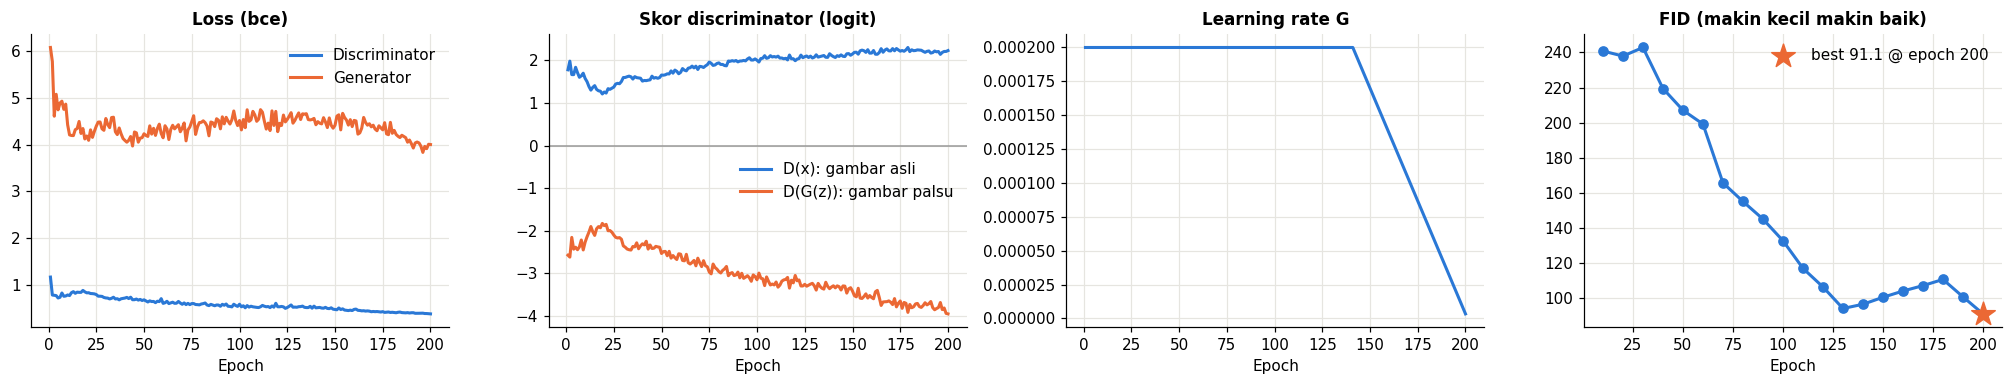

In [11]:
hist = pd.DataFrame(history)
has_fid = "fid" in hist and hist["fid"].notna().any()
panels = ["loss", "skor", "lr"] + (["fid"] if has_fid else []) + (["acc"] if "acc_cls" in hist else [])
fig, axes = plt.subplots(1, len(panels), figsize=(4.6 * len(panels), 3.6), squeeze=False)
ax = dict(zip(panels, axes[0]))

ax["loss"].plot(hist.epoch, hist.loss_D, color=SERIES[0], linewidth=2, label="Discriminator")
ax["loss"].plot(hist.epoch, hist.loss_G, color=SERIES[1], linewidth=2, label="Generator")
ax["loss"].set_title(f"Loss ({CFG['loss']})")
ax["loss"].legend(frameon=False)

ax["skor"].plot(hist.epoch, hist.D_real, color=SERIES[0], linewidth=2, label="D(x): gambar asli")
ax["skor"].plot(hist.epoch, hist.D_fake, color=SERIES[1], linewidth=2, label="D(G(z)): gambar palsu")
ax["skor"].axhline(0, color="#999999", linewidth=1)
ax["skor"].set_title("Skor discriminator (logit)")
ax["skor"].legend(frameon=False)

ax["lr"].plot(hist.epoch, hist.lr_G, color=SERIES[0], linewidth=2)
ax["lr"].set_title("Learning rate G")

if has_fid:
    f = hist.dropna(subset=["fid"])
    best_row = f.loc[f.fid.idxmin()]
    ax["fid"].plot(f.epoch, f.fid, color=SERIES[0], linewidth=2, marker="o", markersize=6)
    ax["fid"].scatter(best_row.epoch, best_row.fid, marker="*", s=260, color=SERIES[1], zorder=3,
                      label=f"best {best_row.fid:.1f} @ epoch {int(best_row.epoch)}")
    ax["fid"].set_title("FID (makin kecil makin baik)")
    ax["fid"].legend(frameon=False)

if "acc" in ax:
    ax["acc"].plot(hist.epoch, hist.acc_cls, color=SERIES[0], linewidth=2)
    ax["acc"].set_ylim(0, 1)
    ax["acc"].set_title("Akurasi kelas D (AC) di gambar asli")

for a in axes[0]:
    a.set_xlabel("Epoch")
fig.tight_layout()
fig.savefig(OUT / "metrik.png")
plt.show()

## Cell 11 — Hasil akhir

Semua hasil di cell ini memakai **`best.pt`** (model dengan FID terbaik).

Keragaman diukur dengan dua cara:
- **RMSE pixel**: cara lama, kasar, dan cenderung terlalu optimis.
- **LPIPS**: jarak perseptual, lebih mendekati penilaian mata manusia.

Rasio jauh di bawah 1 berarti gambar palsu terlalu mirip satu sama lain.

Memakai best.pt dari epoch 200 | FID 91.05899810791016


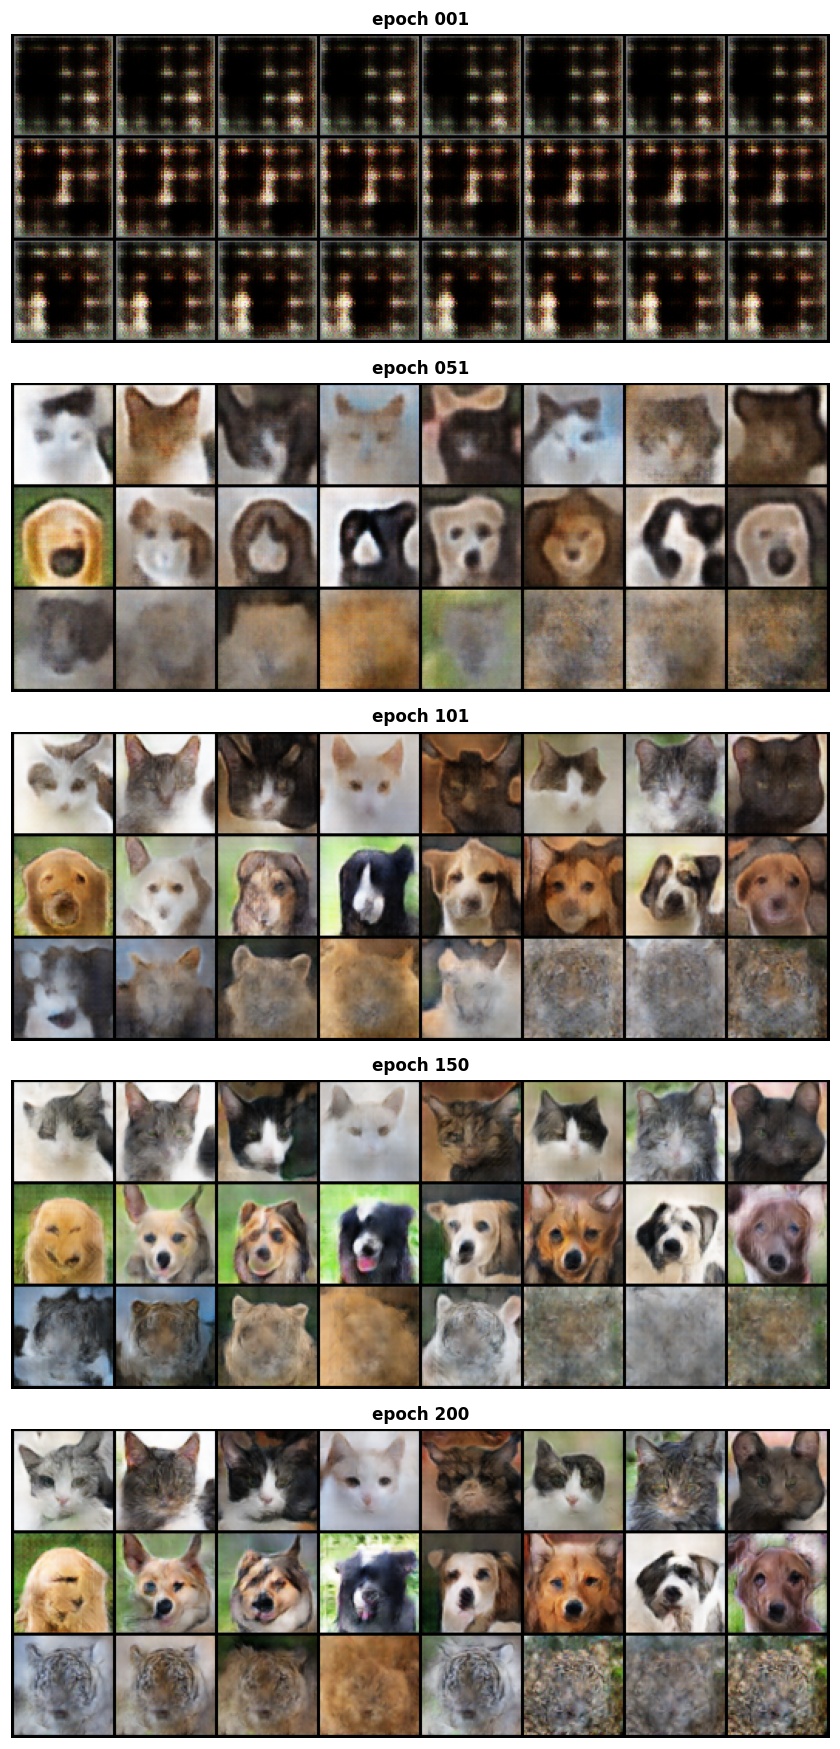

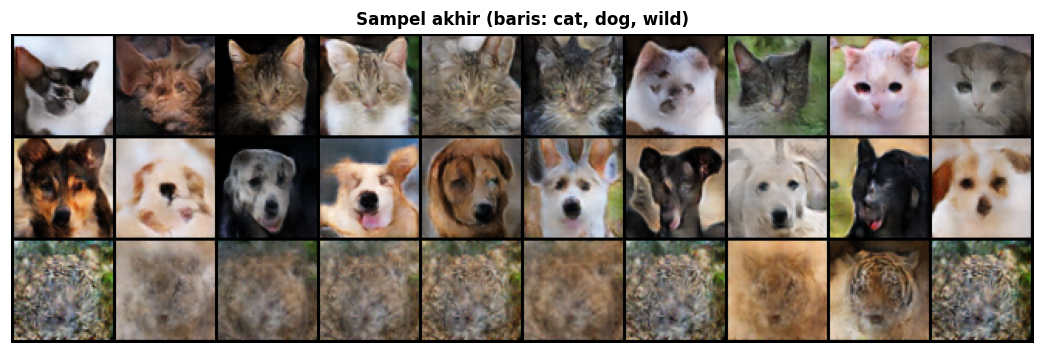

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 194MB/s]


,kelas,rmse_asli,rmse_palsu,rasio_rmse,lpips_asli,lpips_palsu,rasio_lpips
0,cat,0.3595,0.3235,0.900,0.3842,0.3719,0.968
1,dog,0.3516,0.3521,1.001,0.3281,0.3177,0.968
2,wild,0.3017,0.1634,0.542,0.4218,0.3425,0.812


In [12]:
if best_path.exists():
    best = torch.load(best_path, map_location=DEVICE, weights_only=False)
    G_eval.load_state_dict(best["G"])
    print("Memakai best.pt dari epoch", best["epoch"], "| FID", best["fid"])

# 1) Perkembangan dari epoch awal sampai akhir (noise tetap)
sample_files = sorted((OUT / "samples").glob("epoch_*.png"))
picks = sorted({sample_files[i] for i in np.linspace(0, len(sample_files) - 1, 5).round().astype(int)})
fig, axes = plt.subplots(len(picks), 1, figsize=(8, 3.2 * len(picks)), squeeze=False)
for a, path in zip(axes[:, 0], picks):
    a.imshow(Image.open(path))
    a.set_title(path.stem.replace("_", " "))
    a.axis("off")
fig.tight_layout()
fig.savefig(OUT / "perkembangan.png")
plt.show()

# 2) Sampel akhir per kelas (noise ber-seed, jadi bisa direproduksi)
y = torch.arange(N_CLASSES, device=DEVICE).repeat_interleave(10)
final = generate(sample_z(len(y), torch.Generator().manual_seed(CFG["seed"] + 1)), y)
save_image(final, OUT / "sampel_akhir.png", nrow=10, normalize=True, value_range=(-1, 1))
plt.figure(figsize=(12, 4))
plt.imshow(make_grid(final.cpu(), nrow=10, normalize=True, value_range=(-1, 1)).permute(1, 2, 0))
plt.axis("off")
plt.title("Sampel akhir (baris: " + ", ".join(CLASSES) + ")")
plt.show()

# 3) Cek mode collapse: keragaman gambar palsu dibanding gambar asli per kelas
lp = None
try:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lpips"], check=True)
    import lpips

    lp = lpips.LPIPS(net="alex", verbose=False).to(DEVICE).eval()
except Exception as e:
    print("LPIPS dilewati:", type(e).__name__, e)


def pair_idx(n, k, seed=0):
    g = torch.Generator().manual_seed(seed)
    a, b = torch.randint(0, n, (k,), generator=g), torch.randint(0, n, (k,), generator=g)
    keep = a != b
    return a[keep], b[keep]


def mean_pair_rmse(x):  # x di [0, 1]
    a, b = pair_idx(len(x), 2000)
    x = x.flatten(1)
    return ((x[a] - x[b]) ** 2).mean(dim=1).sqrt().mean().item()


@torch.no_grad()
def mean_pair_lpips(x):  # x di [0, 1]
    a, b = pair_idx(len(x), 1000)
    vals = [lp(x[a[i:i + 200]].to(DEVICE) * 2 - 1, x[b[i:i + 200]].to(DEVICE) * 2 - 1).flatten().cpu()
            for i in range(0, len(a), 200)]
    return torch.cat(vals).mean().item()


rows = []
for c, cls in enumerate(CLASSES):
    real = images[labels == c][:500].float() / 255
    fake = gen_uint8(G_eval, c, 500, CFG["seed"] + 2 + c).float() / 255
    r, f = mean_pair_rmse(real), mean_pair_rmse(fake)
    row = {"kelas": cls, "rmse_asli": round(r, 4), "rmse_palsu": round(f, 4), "rasio_rmse": round(f / r, 3)}
    if lp is not None:
        lr_, lf = mean_pair_lpips(real), mean_pair_lpips(fake)
        row.update({"lpips_asli": round(lr_, 4), "lpips_palsu": round(lf, 4), "rasio_lpips": round(lf / lr_, 3)})
    rows.append(row)

diversity = pd.DataFrame(rows)
diversity.to_csv(OUT / "keragaman.csv", index=False)
display(diversity)

## Cell 12 — Evaluasi lengkap: FID, KID, Precision & Recall

Dihitung sekali di akhir memakai `torch-fidelity`, dengan protokol yang sama untuk semua run:

| Subset | Gambar asli | Gambar palsu | Metrik |
|---|---|---|---|
| `all (train)` | `fid_samples` gambar train (seed tetap) | `fid_samples` gambar, dibagi rata per kelas | FID, KID, Precision, Recall |
| `all (val)` | semua gambar val | sama dengan di atas | FID, KID (KID lebih bisa dipercaya karena val sedikit) |
| per kelas | semua gambar train kelas itu | `eval_fake_per_class` gambar | FID, KID |

**Precision** mengukur kualitas (sampel palsu yang realistis). **Recall** mengukur cakupan (seberapa banyak variasi data asli yang berhasil ditiru).

Kalau ada checkpoint baseline lama di `/kaggle/input` (`checkpoint.pt` tanpa `run_name`), baseline dievaluasi ulang di sini dengan protokol yang sama, supaya perbandingannya adil. Angka FID 85.2 yang lama dihitung dengan 5k sampel.

In [13]:
class GeneratorV1(nn.Module):
    # Salinan persis Generator dari notebook lama, supaya state_dict checkpoint baseline cocok
    def __init__(self, z_dim, n_classes, embed_dim, base):
        super().__init__()
        self.label_embed = nn.Embedding(n_classes, embed_dim)

        def up(c_in, c_out):
            return [nn.ConvTranspose2d(c_in, c_out, 4, 2, 1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(True)]

        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim + embed_dim, base * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(base * 8), nn.ReLU(True),
            *up(base * 8, base * 4), *up(base * 4, base * 2), *up(base * 2, base),
            nn.ConvTranspose2d(base, 3, 4, 2, 1),
            nn.Tanh(),
        )

    def forward(self, z, y):
        h = torch.cat([z, self.label_embed(y)], dim=1)
        return self.net(h[:, :, None, None])


G_baseline = None
for p in sorted(Path("/kaggle/input").glob("**/checkpoint.pt")):
    try:
        c = torch.load(p, map_location="cpu", weights_only=False)
    except Exception:
        continue
    if "run_name" not in c.get("cfg", {}):
        bc = c["cfg"]
        G_baseline = GeneratorV1(bc["z_dim"], N_CLASSES, bc["embed_dim"], bc["g_base"]).to(DEVICE)
        G_baseline.load_state_dict(c["G"])
        G_baseline.eval()
        print("Baseline lama ditemukan:", p, "| epoch", c["epoch"])
        break
    del c

try:
    import torch_fidelity
except ImportError:
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torch-fidelity"], check=True)
        import torch_fidelity
    except Exception as e:
        torch_fidelity = None
        print("torch-fidelity tidak tersedia, evaluasi lengkap dilewati:", type(e).__name__, e)

EVAL_DIR = WORK_DIR / "eval_tmp"


def dump(imgs_uint8, folder):
    if folder.exists():
        shutil.rmtree(folder)
    folder.mkdir(parents=True)
    for i, im in enumerate(imgs_uint8):
        Image.fromarray(im.permute(1, 2, 0).numpy()).save(folder / f"{i:05d}.png")
    return str(folder), len(imgs_uint8)


def fidelity(fake, real, prc=False):
    (fake_dir, n_fake), (real_dir, n_real) = fake, real
    try:
        m = torch_fidelity.calculate_metrics(input1=fake_dir, input2=real_dir, cuda=DEVICE.type == "cuda",
                                             fid=True, kid=True, prc=prc,
                                             kid_subset_size=min(1000, n_fake, n_real), verbose=False)
    except Exception as e:
        print("  gagal:", type(e).__name__, e)
        return {}
    names = {"frechet_inception_distance": "FID", "kernel_inception_distance_mean": "KID",
             "precision": "precision", "recall": "recall"}
    return {v: float(m[k]) for k, v in names.items() if k in m}


def evaluate(model, name):
    n_pc = CFG["eval_fake_per_class"]
    fakes = [gen_uint8(model, c, n_pc, CFG["seed"] + 100 + c) for c in range(N_CLASSES)]
    per = math.ceil(CFG["fid_samples"] / N_CLASSES)
    fake_all = dump(torch.cat([f[:per] for f in fakes])[:CFG["fid_samples"]], EVAL_DIR / f"{name}_fake_all")
    res = {"all (train)": fidelity(fake_all, real_dirs["all"], prc=True)}
    if "val" in real_dirs:
        res["all (val)"] = fidelity(fake_all, real_dirs["val"])
    for c, cls in enumerate(CLASSES):
        res[cls] = fidelity(dump(fakes[c], EVAL_DIR / f"{name}_fake_{cls}"), real_dirs[cls])
    return res


eval_results = {}
if torch_fidelity is not None:
    real_idx_eval = torch.randperm(len(images), generator=torch.Generator().manual_seed(1234))[:CFG["fid_samples"]]
    real_dirs = {"all": dump(images[real_idx_eval], EVAL_DIR / "real_all")}
    for c, cls in enumerate(CLASSES):
        real_dirs[cls] = dump(images[labels == c], EVAL_DIR / f"real_{cls}")
    if val_images is not None:
        real_dirs["val"] = dump(val_images, EVAL_DIR / "real_val")

    models = {"run": G_eval}
    if G_baseline is not None:
        models["baseline"] = G_baseline
    for name, m in models.items():
        print("Evaluasi:", name)
        eval_results[name] = evaluate(m, name)

    (OUT / "eval.json").write_text(json.dumps(eval_results["run"], indent=1))
    if "baseline" in eval_results:
        (OUT / "eval_baseline.json").write_text(json.dumps(eval_results["baseline"], indent=1))

    table = pd.DataFrame([{"model": n, "subset": s, **v} for n, r in eval_results.items() for s, v in r.items()])
    display(table.round(4))
    shutil.rmtree(EVAL_DIR, ignore_errors=True)

Evaluasi: run


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


,model,subset,FID,KID,precision,recall
0,run,all (train),90.8747,0.0480,0.6253,0.0134
1,run,all (val),97.6422,0.0476,NaN,NaN
2,run,cat,50.5598,0.0359,NaN,NaN
3,run,dog,67.0538,0.0551,NaN,NaN
4,run,wild,207.7175,0.1733,NaN,NaN


## Cell 13 — Classifier: akurasi kondisional & nearest neighbor

ResNet18 (pretrained ImageNet) di-fine-tune untuk membedakan cat/dog/wild, lalu dipakai untuk dua hal:
1. **Akurasi kondisional**: apakah gambar yang dibuat dengan label X memang dikenali sebagai X? Confusion matrix menunjukkan kelas mana yang tertukar (misalnya dog yang mirip rubah dari kelas wild).
2. **Nearest neighbor**: untuk beberapa sampel palsu, cari 3 gambar training yang paling mirip. Kalau sampel palsu nyaris identik dengan gambar training, berarti model menghafal.

`classifier.pt` disimpan dan ikut masuk zip. Tambahkan sebagai input di run berikutnya supaya tidak perlu dilatih ulang.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 166MB/s]


Classifier epoch 1 | loss 0.003 | akurasi val 0.9953 | 21 dtk
Classifier epoch 2 | loss 0.001 | akurasi val 0.9960 | 15 dtk
Classifier epoch 3 | loss 0.001 | akurasi val 0.9967 | 15 dtk
Classifier epoch 4 | loss 0.006 | akurasi val 0.9947 | 15 dtk
Akurasi classifier di val: 0.9947


,model,kelas,akurasi,confidence
0,run,cat,0.973,0.9641
1,run,dog,0.968,0.9561
2,run,wild,1.000,0.9884


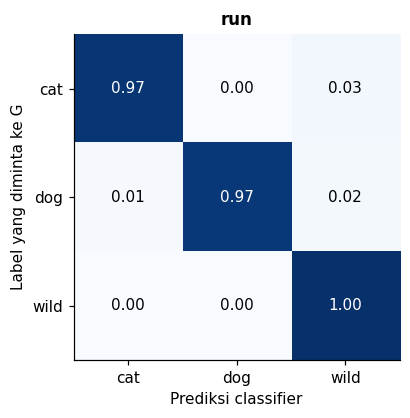

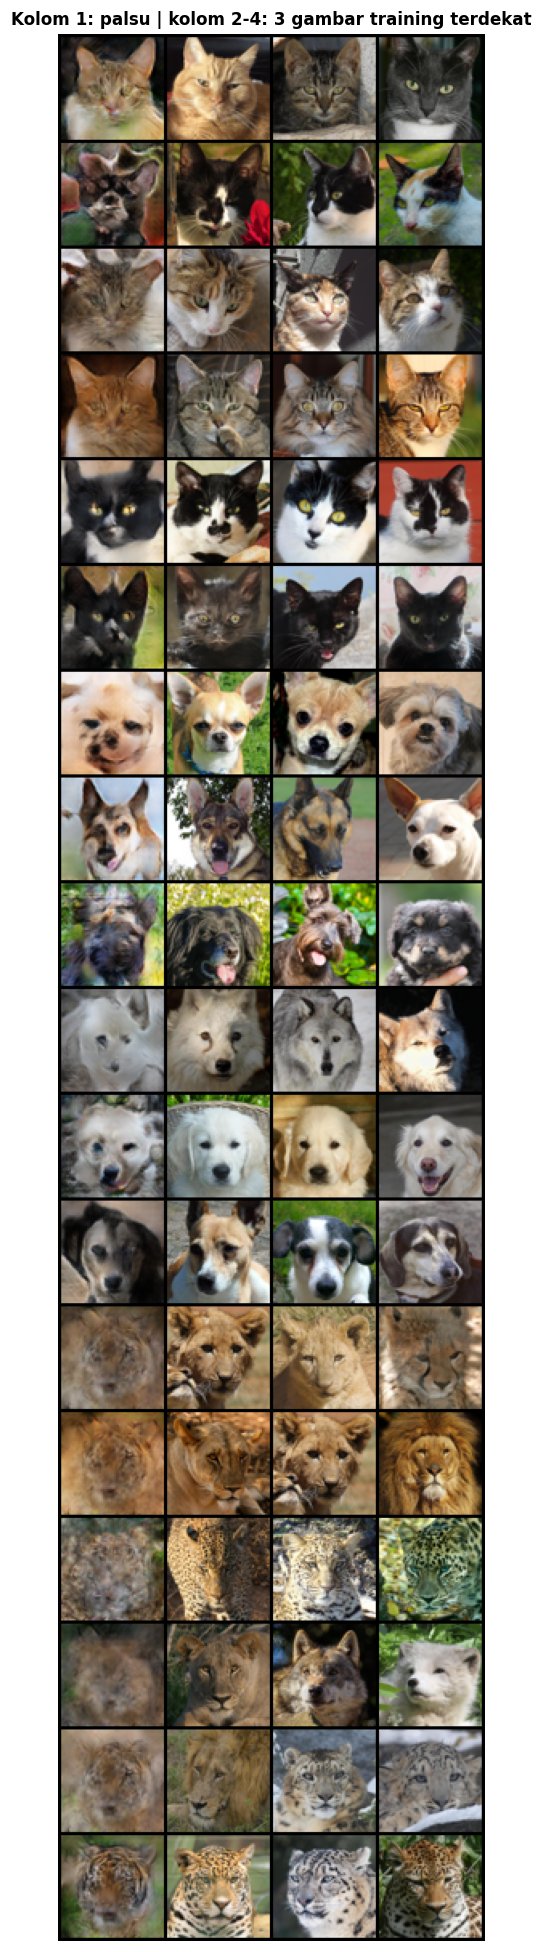

Rata-rata cosine similarity ke tetangga terdekat: 0.8575


In [14]:
import torchvision

CLF_PATH = WORK_DIR / "classifier.pt"
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)


def clf_in(x01):
    return (F.interpolate(x01.float(), size=128, mode="bilinear", align_corners=False) - MEAN) / STD


def build_clf(pretrained):
    weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    m = torchvision.models.resnet18(weights=weights)
    m.fc = nn.Linear(m.fc.in_features, N_CLASSES)
    return m.to(DEVICE)


@torch.no_grad()
def clf_probs(x01, bs=500):
    clf.eval()
    return torch.cat([F.softmax(clf(clf_in(x01[i:i + bs].to(DEVICE))), dim=1).cpu() for i in range(0, len(x01), bs)])


def val_accuracy():
    if val_images is None:
        return float("nan")
    return (clf_probs(val_images.float() / 255).argmax(1) == val_labels).float().mean().item()


found = [CLF_PATH] if CLF_PATH.exists() else sorted(Path("/kaggle/input").glob("**/classifier.pt"))
if found:
    clf = build_clf(False)
    clf.load_state_dict(torch.load(found[0], map_location=DEVICE))
    print("Classifier dipakai ulang dari", found[0])
else:
    try:
        clf = build_clf(True)
    except Exception as e:
        print("Bobot pretrained gagal diunduh, classifier dilatih dari nol:", type(e).__name__, e)
        clf = build_clf(False)
    opt_c = torch.optim.Adam(clf.parameters(), lr=1e-4)
    for ep in range(1, CFG["clf_epochs"] + 1):
        clf.train()
        t0 = time.time()
        for imgs, y in loader:
            loss = F.cross_entropy(clf(clf_in((prepare_batch(imgs) + 1) / 2)), y.to(DEVICE))
            opt_c.zero_grad(set_to_none=True)
            loss.backward()
            opt_c.step()
        print(f"Classifier epoch {ep} | loss {loss.item():.3f} | akurasi val {val_accuracy():.4f} | {time.time() - t0:.0f} dtk")
    torch.save(clf.state_dict(), CLF_PATH)
print("Akurasi classifier di val:", round(val_accuracy(), 4))


# 1) Akurasi kondisional + confusion matrix
def conditional_report(model, name, n=1000):
    conf = np.zeros((N_CLASSES, N_CLASSES))
    rows = []
    for c, cls in enumerate(CLASSES):
        p = clf_probs(gen_uint8(model, c, n, CFG["seed"] + 200 + c).float() / 255)
        conf[c] = torch.bincount(p.argmax(1), minlength=N_CLASSES).numpy() / n
        rows.append({"model": name, "kelas": cls, "akurasi": round(conf[c, c], 4),
                     "confidence": round(p[:, c].mean().item(), 4)})
    return pd.DataFrame(rows), conf


cond_models = {"run": G_eval}
if G_baseline is not None:
    cond_models["baseline"] = G_baseline
reports, confs = [], {}
for name, m in cond_models.items():
    df, confs[name] = conditional_report(m, name)
    reports.append(df)
cond = pd.concat(reports, ignore_index=True)
cond.to_csv(OUT / "akurasi_kondisional.csv", index=False)
display(cond)

fig, axes = plt.subplots(1, len(confs), figsize=(4.4 * len(confs), 3.9), squeeze=False)
for a, (name, conf) in zip(axes[0], confs.items()):
    a.imshow(conf, cmap="Blues", vmin=0, vmax=1)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            a.text(j, i, f"{conf[i, j]:.2f}", ha="center", va="center",
                   color="white" if conf[i, j] > 0.5 else "black")
    a.set_xticks(range(N_CLASSES), CLASSES)
    a.set_yticks(range(N_CLASSES), CLASSES)
    a.set_xlabel("Prediksi classifier")
    a.set_ylabel("Label yang diminta ke G")
    a.set_title(name)
    a.grid(False)
fig.tight_layout()
fig.savefig(OUT / "confusion_matrix.png")
plt.show()

# 2) Nearest neighbor di ruang fitur classifier (cosine similarity)
clf.eval()
feat_net = nn.Sequential(*list(clf.children())[:-1])


@torch.no_grad()
def embed_feats(x01, bs=500):
    return torch.cat([F.normalize(feat_net(clf_in(x01[i:i + bs].to(DEVICE))).flatten(1), dim=1).cpu()
                      for i in range(0, len(x01), bs)])


train_feats = torch.cat([embed_feats(images[i:i + 2000].float() / 255) for i in range(0, len(images), 2000)])
nn_fakes = torch.cat([gen_uint8(G_eval, c, 6, CFG["seed"] + 300 + c) for c in range(N_CLASSES)]).float() / 255
top = (embed_feats(nn_fakes) @ train_feats.T).topk(3, dim=1)
tiles = []
for i in range(len(nn_fakes)):
    tiles.append(nn_fakes[i])
    tiles += [images[j].float() / 255 for j in top.indices[i]]
save_image(torch.stack(tiles), OUT / "nearest_neighbor.png", nrow=4, padding=2)
plt.figure(figsize=(5, 1.3 * len(nn_fakes)))
plt.imshow(make_grid(torch.stack(tiles), nrow=4, padding=2).permute(1, 2, 0))
plt.axis("off")
plt.title("Kolom 1: palsu | kolom 2-4: 3 gambar training terdekat")
plt.show()
print("Rata-rata cosine similarity ke tetangga terdekat:", round(top.values[:, 0].mean().item(), 4))

## Cell 14 — Visualisasi untuk laporan

1. **Truncation trick**: z dibatasi ke |z| ≤ ψ. Makin kecil ψ, sampel makin bersih tapi makin seragam. Kalau FID aktif, FID dengan ψ = 0.7 juga dihitung supaya trade-off-nya terlihat dalam angka.
2. **Label swap**: setiap kolom memakai noise z yang sama dengan label berbeda (baris = kelas). Ini menunjukkan z mengatur pose/warna, sedangkan label mengatur jenis hewan.
3. **Interpolasi latent**: transisi mulus antara dua z (slerp) pada kelas yang sama.

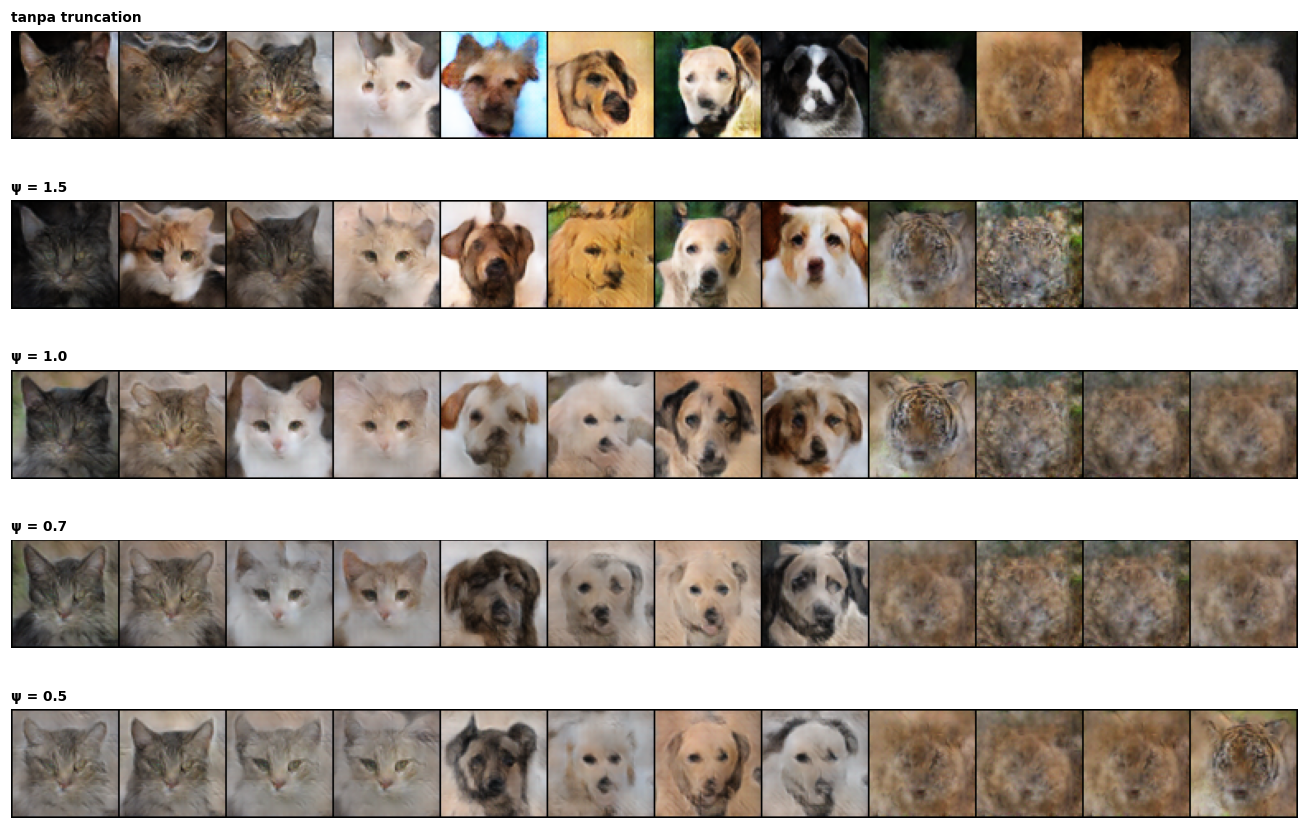

FID tanpa truncation vs ψ = 0.7: {'tanpa': 91.06, 'psi_0.7': 119.86}


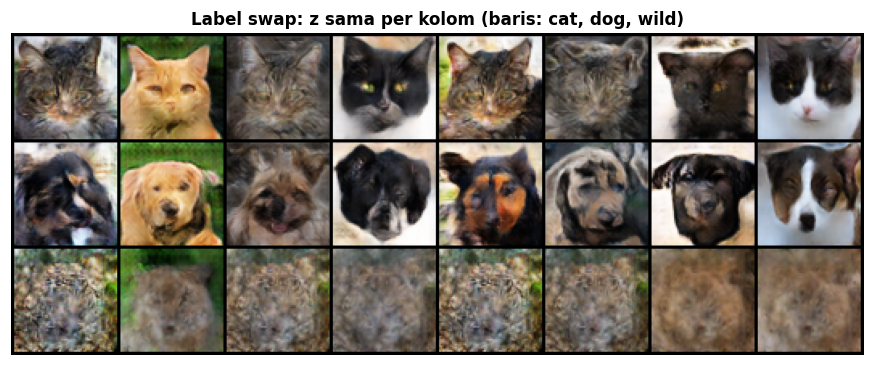

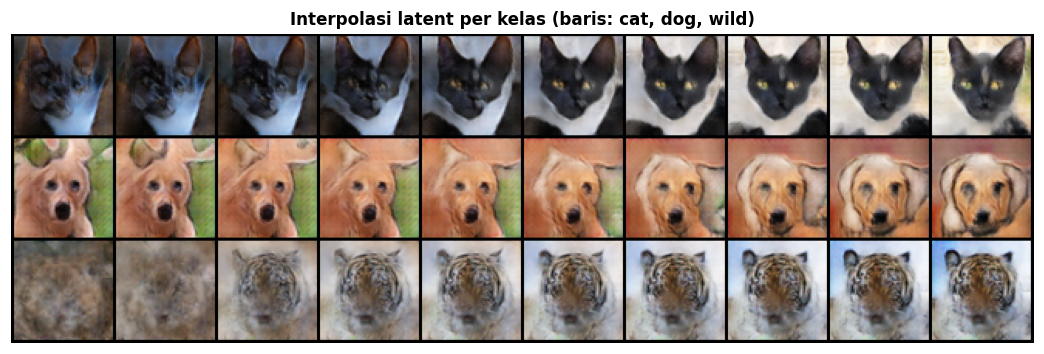

In [15]:
# 1) Truncation trick
TRUNCS = [None, 1.5, 1.0, 0.7, 0.5]
fig, axes = plt.subplots(len(TRUNCS), 1, figsize=(12, 1.6 * len(TRUNCS)), squeeze=False)
y = torch.arange(N_CLASSES, device=DEVICE).repeat_interleave(4)
for a, t in zip(axes[:, 0], TRUNCS):
    imgs_t = generate(sample_z(len(y), torch.Generator().manual_seed(CFG["seed"] + 3), t), y).cpu()
    a.imshow(make_grid(imgs_t, nrow=len(y), padding=1, normalize=True, value_range=(-1, 1)).permute(1, 2, 0))
    a.set_title("tanpa truncation" if t is None else f"ψ = {t}", fontsize=9, loc="left")
    a.axis("off")
fig.tight_layout()
fig.savefig(OUT / "truncation.png")
plt.show()

if fid_enabled:
    trunc_fid = {"tanpa": compute_fid(), "psi_0.7": compute_fid(trunc=0.7)}
    (OUT / "truncation_fid.json").write_text(json.dumps(trunc_fid, indent=1))
    print("FID tanpa truncation vs ψ = 0.7:", {k: round(v, 2) for k, v in trunc_fid.items()})

# 2) Label swap: kolom = noise yang sama, baris = kelas
z = sample_z(8, torch.Generator().manual_seed(CFG["seed"] + 4)).repeat(N_CLASSES, 1)
y = torch.arange(N_CLASSES, device=DEVICE).repeat_interleave(8)
swap = generate(z, y)
save_image(swap, OUT / "label_swap.png", nrow=8, normalize=True, value_range=(-1, 1))
plt.figure(figsize=(10, 4))
plt.imshow(make_grid(swap.cpu(), nrow=8, normalize=True, value_range=(-1, 1)).permute(1, 2, 0))
plt.axis("off")
plt.title("Label swap: z sama per kolom (baris: " + ", ".join(CLASSES) + ")")
plt.show()


# 3) Interpolasi latent (slerp)
def slerp(a, b, t):
    a_n, b_n = F.normalize(a, dim=-1), F.normalize(b, dim=-1)
    omega = torch.acos((a_n * b_n).sum(-1, keepdim=True).clamp(-1 + 1e-7, 1 - 1e-7))
    so = torch.sin(omega)
    return torch.sin((1 - t) * omega) / so * a + torch.sin(t * omega) / so * b


g = torch.Generator().manual_seed(CFG["seed"] + 5)
steps = torch.linspace(0, 1, 10, device=DEVICE)[:, None]
interp = torch.cat([generate(slerp(sample_z(1, g), sample_z(1, g), steps), torch.full((10,), c, device=DEVICE))
                    for c in range(N_CLASSES)])
save_image(interp, OUT / "interpolasi.png", nrow=10, normalize=True, value_range=(-1, 1))
plt.figure(figsize=(12, 4))
plt.imshow(make_grid(interp.cpu(), nrow=10, normalize=True, value_range=(-1, 1)).permute(1, 2, 0))
plt.axis("off")
plt.title("Interpolasi latent per kelas (baris: " + ", ".join(CLASSES) + ")")
plt.show()

## Cell 15 — Perbandingan antar run

Tambahkan output run lain lewat **Add Input**. Cell ini membaca semua `history.csv` (ditambah `eval.json` dan `akurasi_kondisional.csv` kalau ada), lalu membuat grafik FID gabungan dan tabel ablation.

Untuk perbandingan yang adil, pakai kolom `(eval)` dari Cell 12. Kolom `(history)` milik baseline lama dihitung dengan 5k sampel, sedangkan run baru memakai 10k.

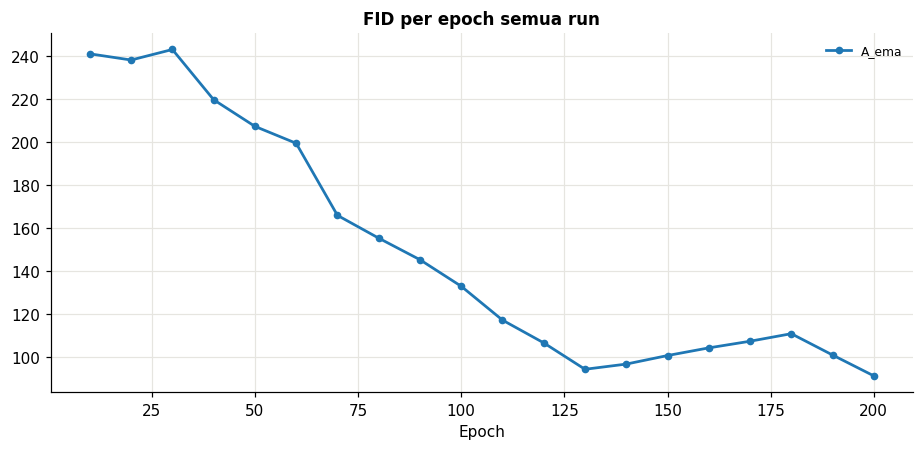

,run,epoch,detik/epoch,FID akhir (history),FID best (history),FID (eval),KID (eval),precision (eval),recall (eval),akurasi_kondisional
0,A_ema,200,17.8,91.06,91.06,90.8747,0.048,0.6253,0.0134,0.9803


In [16]:
run_dirs = {}
for hp in sorted(Path("/kaggle/input").glob("**/history.csv")) + [OUT / "history.csv"]:
    if not hp.exists():
        continue
    cfg_file = hp.parent / "config.json"
    name = json.loads(cfg_file.read_text()).get("run_name", "baseline_lama") if cfg_file.exists() else hp.parent.name
    run_dirs[name] = hp.parent  # OUT diproses terakhir, jadi versi sesi ini yang dipakai


def eval_cols(path):
    if not path.exists():
        return {}
    return {f"{k} (eval)": round(v, 4) for k, v in json.loads(path.read_text()).get("all (train)", {}).items()}


def cond_acc(d, model):
    path = d / "akurasi_kondisional.csv"
    if not path.exists():
        return {}
    c = pd.read_csv(path)
    c = c[c.model == model]
    return {"akurasi_kondisional": round(c.akurasi.mean(), 4)} if len(c) else {}


rows = []
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for name, d in run_dirs.items():
    h = pd.read_csv(d / "history.csv")
    row = {"run": name, "epoch": int(h.epoch.max()), "detik/epoch": round(h.detik.mean(), 1)}
    if "fid" in h and h.fid.notna().any():
        f = h.dropna(subset=["fid"])
        ax.plot(f.epoch, f.fid, marker="o", markersize=4, linewidth=1.8, label=name)
        row.update({"FID akhir (history)": round(f.fid.iloc[-1], 2), "FID best (history)": round(f.fid.min(), 2)})
    row.update(eval_cols(d / "eval.json"))
    row.update(cond_acc(d, "run"))
    rows.append(row)

for d in run_dirs.values():  # baseline lama yang dievaluasi ulang dengan protokol baru (Cell 12)
    if (d / "eval_baseline.json").exists():
        rows.append({"run": "baseline_lama (eval ulang)", **eval_cols(d / "eval_baseline.json"),
                     **cond_acc(d, "baseline")})
        break

ax.set_title("FID per epoch semua run")
ax.set_xlabel("Epoch")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "perbandingan_fid.png")
plt.show()

comparison = pd.DataFrame(rows)
comparison.to_csv(OUT / "perbandingan_run.csv", index=False)
display(comparison)

## Cell 16 — Simpan semua hasil

In [17]:
shutil.rmtree(WORK_DIR / "eval_tmp", ignore_errors=True)
if (WORK_DIR / "classifier.pt").exists():
    shutil.copy(WORK_DIR / "classifier.pt", OUT / "classifier.pt")
archive = shutil.make_archive(str(WORK_DIR / f"cgan_{CFG['run_name']}"), "zip", OUT)
print("Semua hasil tersimpan di", archive)

Semua hasil tersimpan di /kaggle/working/cgan_A_ema.zip
